# Mesh morphing

`morph(mesh, displacement)` moves a mesh's boundary (or chosen points) by a prescribed displacement and carries the motion into the rest of the mesh by a harmonic extension, keeping the connectivity: shape optimisation and fluid–structure mesh motion. Jacobian-based stiffening keeps small cells rigid, steps let large motions through, and an inversion guard refuses a result with inverted cells. See `doc/morph.md`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection

import meshioplusplus as mp


def draw(ax, mesh, title, colour='tab:blue'):
    tris = mesh.cells_dict['triangle']
    ax.add_collection(PolyCollection(mesh.points[tris, :2], facecolor='none', edgecolor=colour, lw=0.4))
    ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6); ax.set_aspect('equal'); ax.axis('off'); ax.set_title(title)


def rotate_inner(mesh, degrees, radius=0.3):
    r = np.linalg.norm(mesh.points[:, :2], axis=1)
    inner = np.isclose(r, radius)
    th = np.radians(degrees)
    R = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
    d = np.zeros((len(mesh.points), 3))
    d[inner, :2] = mesh.points[inner, :2] @ R.T - mesh.points[inner, :2]
    return d

## A rotating inner body

The inner circle of an annulus turns; the outer circle stays (its displacement is zero), and the triangles between follow. Up to about 60° any setting works; at 90° the plain Laplace extension turns cells inside out, and with stiffening applied in four steps the mesh stays valid.

stiffening 0, steps 1: 48 inverted cell(s)
stiffening 0, steps 4: 48 inverted cell(s)
stiffening 1, steps 1: 48 inverted cell(s)
stiffening 1, steps 4: 0 inverted cell(s)


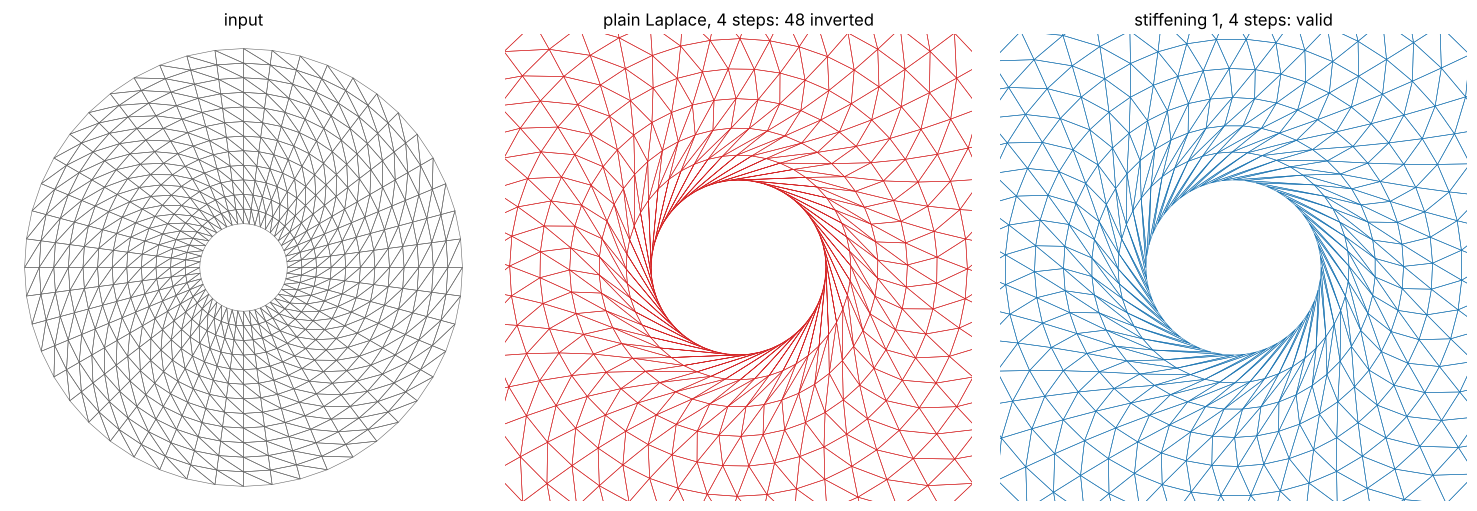

In [2]:
annulus = mp.convert_cells(mp.annulus(inner_radius=0.3, outer_radius=1.5, ntheta=48, nr=12), mode='simplexify')
d90 = rotate_inner(annulus, 90)
rows = []
for stiffening, steps in ((0.0, 1), (0.0, 4), (1.0, 1), (1.0, 4)):
    out, rep = mp.morph(annulus, d90, stiffening=stiffening, steps=steps, allow_inverted=True, return_report=True)
    rows.append((stiffening, steps, rep['num_inverted'], out))
    print(f'stiffening {stiffening:g}, steps {steps}: {rep["num_inverted"]} inverted cell(s)')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
draw(axes[0], annulus, 'input', colour='0.4')
plain = rows[1][3]
draw(axes[1], plain, f'plain Laplace, 4 steps: {rows[1][2]} inverted', colour='tab:red')
draw(axes[2], rows[3][3], 'stiffening 1, 4 steps: valid')
for ax in axes[1:]:
    ax.set_xlim(-0.8, 0.8); ax.set_ylim(-0.8, 0.8)
plt.tight_layout()
plt.show()

## The guard

Without `allow_inverted`, a result with inverted cells is refused with the remedies named.

In [3]:
try:
    mp.morph(annulus, d90, stiffening=0.0)
except ValueError as exc:
    print('refused:', exc)

refused: morph: 48 cell(s) turned inside out; apply the displacement in more steps, raise the stiffening, or pass allow_inverted to keep the result


## The roadmap probe: lifting a hexahedral box's top face

A 6 × 6 × 6 hexahedral box whose top face is pushed up by a bump of height 0.1: the interior rises with it, the bottom stays, and no hexahedron inverts.

{'num_constrained': 218, 'num_free': 125, 'num_inverted': 0, 'max_displacement': 0.10000000000000009}


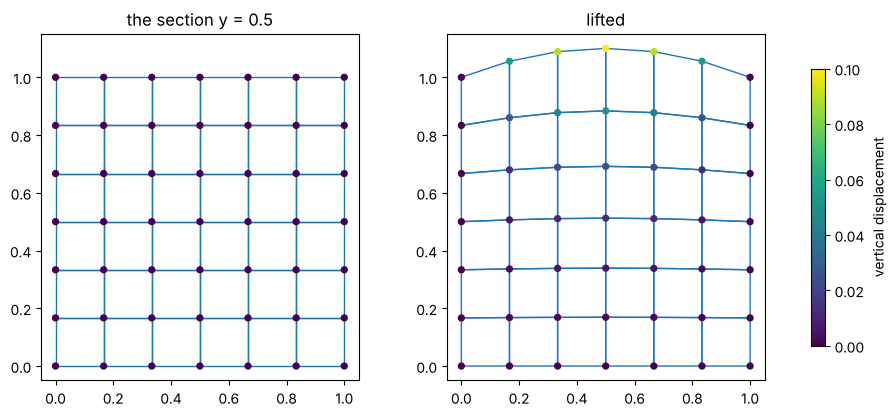

In [4]:
box = mp.box(dims=(6, 6, 6))
x, y, z = box.points.T
d = np.zeros((len(box.points), 3))
top = z == 1.0
d[top, 2] = 0.1 * 16 * x[top] * (1 - x[top]) * y[top] * (1 - y[top])
lifted, rep = mp.morph(box, d, return_report=True)
print({k: rep[k] for k in ('num_constrained', 'num_free', 'num_inverted', 'max_displacement')})

mid = np.isclose(y, 0.5)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, mesh, title in ((axes[0], box, 'the section y = 0.5'), (axes[1], lifted, 'lifted')):
    hexes = mesh.cells_dict['hexahedron']
    keep = np.all(np.isclose(box.points[hexes][:, :, 1], 0.5) | np.isclose(box.points[hexes][:, :, 1], 0.5 + 1 / 6), axis=1)
    quads = hexes[keep][:, [0, 1, 5, 4]]
    ax.add_collection(PolyCollection(mesh.points[quads][:, :, [0, 2]], facecolor='none', edgecolor='tab:blue'))
    rise = (mesh.points[:, 2] - z)[mid]
    sc = ax.scatter(mesh.points[mid, 0], mesh.points[mid, 2], c=rise, cmap='viridis', s=18, zorder=3, vmin=0, vmax=0.1)
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.15); ax.set_aspect('equal'); ax.set_title(title)
plt.colorbar(sc, ax=axes, shrink=0.8, label='vertical displacement')
plt.show()

## In a pipeline, and on the command line

The step is `Morph`; the verb `morph` in both CLIs.

In [5]:
moving = mp.Mesh(annulus.points, annulus.cells, point_data={'d': rotate_inner(annulus, 45)})
_, rep = mp.apply_operations(moving, [{"Op": "Morph", "Array": "d", "Steps": 2}])
print(rep['steps'][0])
print('meshioplusplus morph fluid.vtu fluid_t1.vtu --array wall_motion --steps 4 --json')

{'op': 'Morph', 'NumConstrained': 96.0, 'NumInverted': 0.0, 'MaxDisplacement': 0.22961005941905388, 'Converged': 1.0}
meshioplusplus morph fluid.vtu fluid_t1.vtu --array wall_motion --steps 4 --json
